# Experimental kinetic benchmark for acid-catalysed paracetamol hydrolysis
Chen, G., Ye, J., Bao, H., & Yang, P. (2002). Determination of the rate constants and activation energy of acetaminophen hydrolysis by capillary electrophoresis. *Journal of Pharmaceutical and Biomedical Analysis, 29*, 843–850. https://doi.org/10.1016/S0731-7085(02)00211-X

Data transcribed from Table 2 (p. 850); conditions from Section 2.4 (p. 845). This notebook reproduces published kinetics and derives **apparent** Eyring parameters; no new DFT calculations are represented as results. Install dependencies in your kernel: `pip install numpy pandas scipy matplotlib jupyter`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, scipy, matplotlib as mpl, matplotlib.pyplot as plt
from scipy.stats import linregress, t
from scipy.constants import R, Boltzmann as kB, Planck as h
from importlib.metadata import version
out = Path('paracetamol_kinetics_results'); out.mkdir(exist_ok=True)
for pkg in ['numpy','pandas','scipy','matplotlib']: print(pkg, version(pkg))
# Explicit style fallback: Figentra is not required; serif, bold axes and labels.
mpl.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','Liberation Serif','DejaVu Serif'], 'font.size':12,'font.weight':'bold','axes.labelweight':'bold','axes.linewidth':1.6,'xtick.major.width':1.5,'ytick.major.width':1.5,'xtick.direction':'out','ytick.direction':'out','figure.facecolor':'white','axes.facecolor':'white','savefig.dpi':450})

numpy 2.3.5
pandas 2.2.3
scipy 1.17.0
matplotlib 3.10.8


## 1. Published experimental data
Equal volumes (10 mL each) of 0.1 M paracetamol and 1.0 M HCl were mixed: initial concentrations 0.05 M and 0.5 M respectively. Sampling times: 5, 15, 30, 50, 75 min. Reported rates are apparent first-order constants at fixed initial acid concentration. Table 2 uses temperatures rounded to one decimal place; retain these for exact reproduction. No replicate rate uncertainties are reported.

In [2]:
data=pd.DataFrame({'T_K':[343.2,353.2,363.2,373.2],'k_min_1':[.005027,.008522,.01860,.03276],'half_life_reported_min':[137.88,81.340,37.266,21.158],'time_fit_r':[.9976,.9987,.9981,.9985]})
data['k_s_1']=data.k_min_1/60
data['half_life_recalculated_min']=np.log(2)/data.k_min_1
data['inverse_T']=1/data.T_K
data['ln_k_min']=np.log(data.k_min_1)
data['ln_k_over_T']=np.log(data.k_s_1/data.T_K)
data['apparent_dG_kJ_mol']=R*data.T_K*np.log(kB*data.T_K/(h*data.k_s_1))/1000
data.to_csv(out/'experimental_and_derived.csv',index=False)
data

,T_K,k_min_1,half_life_reported_min,time_fit_r,k_s_1,half_life_recalculated_min,inverse_T,ln_k_min,ln_k_over_T,apparent_dG_kJ_mol
0,343.2,0.005027,137.880,0.9976,0.000084,137.884858,0.002914,-5.292932,-15.225590,111.246236
1,353.2,0.008522,81.340,0.9987,0.000142,81.336210,0.002831,-4.765104,-14.726483,113.021966
2,363.2,0.018600,37.266,0.9981,0.000310,37.265977,0.002753,-3.984594,-13.973892,113.949224
3,373.2,0.032760,21.158,0.9985,0.000546,21.158339,0.002680,-3.418547,-13.435006,115.414452


## 2. Arrhenius and Eyring regressions
Unweighted ordinary least squares, four points, two residual degrees of freedom. Confidence intervals reflect regression scatter only, not experimental measurement uncertainty. Eyring analysis assumes unit transmission coefficient; apparent parameters include any temperature-dependent speciation and solvent contributions.

In [3]:
x=data.inverse_T.to_numpy(); n=len(x); crit=t.ppf(.975,n-2)
a=linregress(x,data.ln_k_min); e=linregress(x,data.ln_k_over_T)
Ea=-a.slope*R/1000; H=-e.slope*R/1000; S=R*(e.intercept-np.log(kB/h)); A=np.exp(a.intercept)
rows=[]
for name,val,se in [('Ea [kJ/mol]',Ea,a.stderr*R/1000),('Apparent dH‡ [kJ/mol]',H,e.stderr*R/1000),('Apparent dS‡ [J/mol/K]',S,e.intercept_stderr*R)]:
    rows.append([name,val,se,val-crit*se,val+crit*se])
summary=pd.DataFrame(rows,columns=['parameter','estimate','SE','CI95_low','CI95_high'])
summary.to_csv(out/'regression_summary.csv',index=False)
print(f'Arrhenius: slope={a.slope:.6f} K; intercept={a.intercept:.6f}; R²={a.rvalue**2:.6f}; A={A:.6g} min^-1')
print(f'Eyring R²={e.rvalue**2:.6f}')
print(f'Reproduced published Ea using R=8.314: {-a.slope*8.314/1000:.2f} kJ/mol')
summary

Arrhenius: slope=-8195.107112 K; intercept=18.535610; R²=0.993180; A=1.12179e+08 min^-1
Eyring R²=0.992594
Reproduced published Ea using R=8.314: 68.13 kJ/mol


,parameter,estimate,SE,CI95_low,CI95_high
0,Ea [kJ/mol],68.137912,3.992689,50.958760,85.317064
1,Apparent dH‡ [kJ/mol],65.163773,3.980027,48.039098,82.288447
2,Apparent dS‡ [J/mol/K],-134.685264,11.127455,-182.562841,-86.807688


/tmp/ipykernel_1408/3112548991.py:28: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Liberation Serif.
  fig.savefig(out/'arrhenius_eyring_v2.png',dpi=450,bbox_inches='tight',pad_inches=.16)


/tmp/ipykernel_1408/3112548991.py:29: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Liberation Serif.
  fig.savefig(out/'arrhenius_eyring_v2.pdf',bbox_inches='tight',pad_inches=.16)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Liberation Serif.
  fig.canvas.print_figure(bytes_io, **kw)


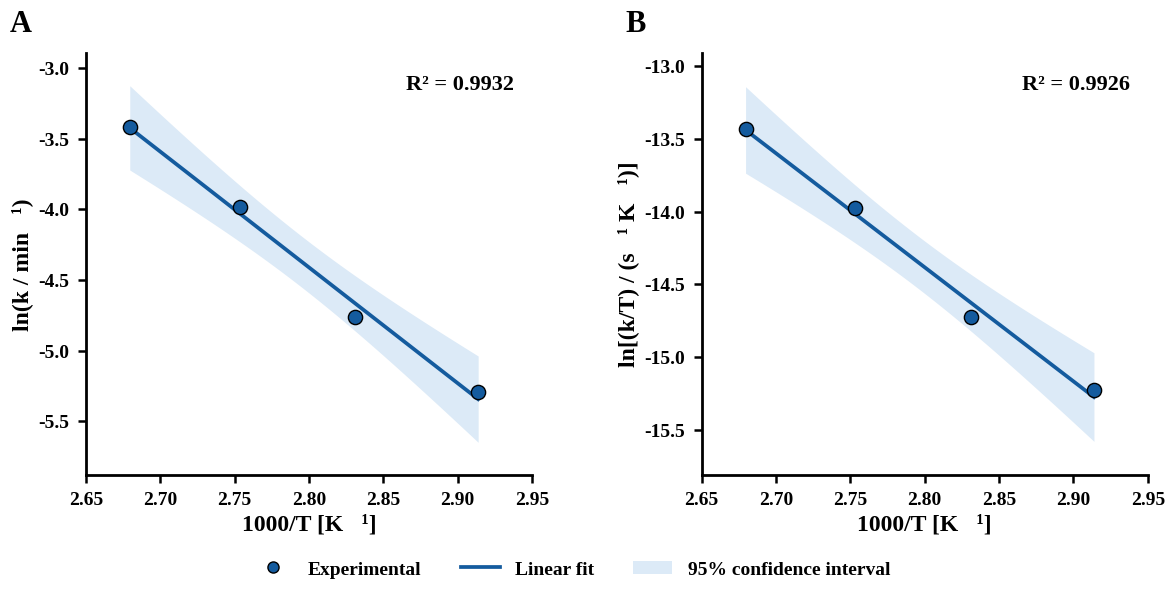

In [4]:
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
mpl.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','Liberation Serif','DejaVu Serif'], 'font.size':15,'font.weight':'bold','axes.labelweight':'bold','axes.labelsize':17,'axes.linewidth':2.0,'xtick.major.width':1.8,'ytick.major.width':1.8,'xtick.major.size':6,'ytick.major.size':6,'xtick.labelsize':14,'ytick.labelsize':14,'mathtext.fontset':'stix','figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white','savefig.dpi':450})
blue='#145B9E'
def plot_fit(ax,y,fit,ylabel,panel):
    xx=np.linspace(x.min(),x.max(),400); yy=fit.intercept+fit.slope*xx
    residual=y-(fit.intercept+fit.slope*x)
    s=np.sqrt(np.sum(residual**2)/(n-2)); band=crit*s*np.sqrt(1/n+(xx-x.mean())**2/np.sum((x-x.mean())**2))
    ax.fill_between(xx*1000,yy-band,yy+band,color='#DCEAF7',linewidth=0,zorder=1)
    ax.plot(xx*1000,yy,color=blue,lw=2.7,zorder=2)
    ax.scatter(x*1000,y,s=105,color=blue,edgecolor='black',linewidth=1.0,zorder=3)
    ax.set(xlabel='1000/T [K⁻¹]',ylabel=ylabel,xlim=(2.65,2.95))
    ax.xaxis.set_major_locator(MultipleLocator(.05)); ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax.yaxis.set_major_locator(MultipleLocator(.5)); ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    lo,hi=(yy-band).min(),(yy+band).max(); ax.set_ylim(lo-.23,hi+.23)
    ax.text(-.17,1.035,panel,transform=ax.transAxes,fontsize=22,fontweight='bold',va='bottom')
    ax.text(.96,.95,f'R² = {fit.rvalue**2:.4f}',transform=ax.transAxes,ha='right',va='top',fontsize=16)
    ax.tick_params(direction='out',pad=6)
    for spine in ['top','right']: ax.spines[spine].set_visible(False)
    for tick in ax.get_xticklabels()+ax.get_yticklabels(): tick.set_fontweight('bold')
fig,axs=plt.subplots(1,2,figsize=(12,6.2))
fig.subplots_adjust(left=.095,right=.98,bottom=.22,top=.90,wspace=.38)
plot_fit(axs[0],data.ln_k_min.to_numpy(),a,'ln(k / min⁻¹)','A')
plot_fit(axs[1],data.ln_k_over_T.to_numpy(),e,'ln[(k/T) / (s⁻¹ K⁻¹)]','B')
handles=[Line2D([],[],marker='o',linestyle='none',markerfacecolor=blue,markeredgecolor='black',markersize=8,label='Experimental'),Line2D([],[],color=blue,lw=2.7,label='Linear fit'),Patch(facecolor='#DCEAF7',label='95% confidence interval')]
fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,.025),ncol=3,frameon=False,prop={'weight':'bold','size':14})
fig.savefig(out/'arrhenius_eyring_v2.png',dpi=450,bbox_inches='tight',pad_inches=.16)
fig.savefig(out/'arrhenius_eyring_v2.pdf',bbox_inches='tight',pad_inches=.16)
plt.show()


## 3. DFT pathway design (prospective, not computed)
Start with carbonyl-O protonation as a hypothesis; compare N-protonation as a sensitivity check. For each fixed cluster composition, examine water attack on the carbonyl carbon, direct or water-relayed proton transfer to form a tetrahedral intermediate, then proton transfer to nitrogen and C–N cleavage. Product reference: p-aminophenol protonated on N and neutral acetic acid. Balance atoms and total charge (+1 without chloride) within each pathway; use the same number of water molecules on both sides. When chloride is explicitly included, compare only matched neutral clusters and test several ion placements. Treat bulk water with a consistent aqueous continuum (e.g. CPCM), not as a representation of 0.5 M electrolyte by itself.

Pilot design: 1, 2, 3 and 4 explicit waters around protonated paracetamol (one is the nucleophile); at least five distinct starting arrangements at each size, deduplicate optimised structures. Hydronium plus neutral substrate is an alternative protonation reference with atom balance. Screen with a lower-cost method, then optimise selected minima and transition states at a consistent dispersion-corrected DFT level; verify minima with zero imaginary frequencies, transition states with one relevant imaginary mode, and IRC endpoints. Test higher-level single points and basis sensitivity. Expand water count/configurations if barrier ranking changes or if ensemble barrier changes exceed a prospective 4 kJ/mol tolerance across two successive sizes. This is a planning criterion, not evidence of convergence. Keep cluster sizes separate unless water chemical potential and standard states are explicitly accounted for.

Compute thermal enthalpies and free energies at the four published temperatures; use consistent solution standard states, quasi-harmonic sensitivity for low modes, and water activity conventions. Treat protonation equilibrium with an independently justified solution pKa(T) or balanced thermodynamic cycle and acid activity. Do not equate 0.5 M directly with thermodynamic activity without stating an approximation. Under rapid pre-equilibrium and irreversible rate-controlling addition, k_obs = f_protonated × sum(p_i k_i); p_i are conditional hydration populations and k_i are TST rates. If downstream steps compete, use a microkinetic model rather than assume addition controls the rate. Acid consumption by product protonation may reduce free acid during conversion; assess sensitivity. If adequate sampling/speciation is unavailable, report conditional barriers only, not quantitatively validated rates. Regress predicted ln(k_obs) against 1/T and compare with experimental apparent Ea, Eyring parameters and measured rates. Four temperatures cannot uniquely identify mechanism.

In [5]:
# Optional comparison function for future DFT-derived observed rates (s^-1).
# No placeholder predictions are generated.
def compare_dft_rates(k_pred_s):
    k_pred_s=np.asarray(k_pred_s,dtype=float)
    if k_pred_s.shape!=(4,) or not np.all(np.isfinite(k_pred_s)&(k_pred_s>0)): raise ValueError('Supply four positive finite predicted rates in s^-1 in Table 2 temperature order.')
    fit=linregress(x,np.log(k_pred_s)); ef=linregress(x,np.log(k_pred_s/data.T_K))
    logerr=np.log(k_pred_s/data.k_s_1.to_numpy())
    return {'Ea_pred_kJ_mol':-R*fit.slope/1000,'Ea_error_kJ_mol':-R*fit.slope/1000-Ea,'dH_app_pred_kJ_mol':-R*ef.slope/1000,'dS_app_pred_J_mol_K':R*(ef.intercept-np.log(kB/h)),'RMSE_ln_rate':np.sqrt(np.mean(logerr**2))}
print('Ready for future DFT results; no predicted rates supplied.')

Ready for future DFT results; no predicted rates supplied.
